In [25]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080219

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")


[Conda 环境] spider_env
[学号] 20244080219
[机器指纹] 94c2312533b046bb
[RUN_ID] 20244080219-94c2312533b046bb


围绕半圆定律 Wigner 矩阵

导入依赖

In [26]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(2024)   # 结果可复现，方便写说明
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


任务 1：`wigner_density(x)`

In [27]:
def wigner_density(x):
    """半圆密度 f(x)：|x|<=2 时为 sqrt(4-x^2)/(2π)，否则为 0。
    同时支持 Python 标量和 NumPy 标量/数组，标量输入返回 float。"""
    x = np.asarray(x, dtype=float)
    density = np.zeros_like(x)
    mask = np.abs(x) <= 2.0
    density[mask] = np.sqrt(4.0 - x[mask] ** 2) / (2.0 * np.pi)
    return density.item() if density.ndim == 0 else density   # 标量返回 Python float

# 简单自测
print(wigner_density(0))          # 0.3183（= 1/π，理论峰值）
print(wigner_density(-2.0))       # 0.0
print(wigner_density(2.5))        # 0.0（区间外）
print(type(wigner_density(np.int64(1))))  # <class 'float'>


0.3183098861837907
0.0
0.0
<class 'float'>


任务 2：`generate_wigner(n)`


In [28]:
def generate_wigner(n):
    """生成 n×n Wigner 矩阵：上三角元素 ~ N(0, 1/n)，下三角镜像对称。"""
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")
    z = np.random.normal(loc=0.0, scale=np.sqrt(1.0 / n), size=(n, n))
    # 只保留上三角（含对角线）并镜像到下三角，保证 Z_ij = Z_ji 且元素方差为 1/n
    return np.triu(z) + np.triu(z, 1).T

# 自测
Z = generate_wigner(5)
print(Z)
print("是否对称：", np.allclose(Z, Z.T), "| 形状：", Z.shape)

for bad in [3.5, "10", "abc"]:
    try:
        generate_wigner(bad)
    except TypeError as e:
        print(f"输入 {bad!r} -> TypeError: {e}")
for bad in [0, -2]:
    try:
        generate_wigner(bad)
    except ValueError as e:
        print(f"输入 {bad!r} -> ValueError: {e}")


[[ 0.74597344  0.32975193 -0.09013043 -0.06748987  0.40967082]
 [ 0.32975193 -1.17168263 -0.59268975  0.20571316  0.04563888]
 [-0.09013043 -0.59268975 -0.67110438 -0.12425011  0.53397081]
 [-0.06748987  0.20571316 -0.12425011  0.42202534 -0.34270454]
 [ 0.40967082  0.04563888  0.53397081 -0.34270454  0.44311994]]
是否对称： True | 形状： (5, 5)
输入 3.5 -> TypeError: n 必须是整数
输入 '10' -> TypeError: n 必须是整数
输入 'abc' -> TypeError: n 必须是整数
输入 0 -> ValueError: n 必须是正整数
输入 -2 -> ValueError: n 必须是正整数


任务 3：`get_spectrum(matrix)`

In [29]:
def get_spectrum(matrix):
    """返回矩阵全部特征值，按非递减顺序排列的 NumPy 数组。
    矩阵对称，用 eigvalsh 比 eig 更快更准。"""
    a = np.asarray(matrix, dtype=float)
    return np.sort(np.linalg.eigvalsh(a))

# 自测：对角矩阵的特征值应有序返回
m = np.array([[3, 0, 0], [0, 1, 0], [0, 0, 2]])
print(get_spectrum(m))   # [1. 2. 3.]


[1. 2. 3.]


任务 4：4 张子图 n=100,200,500,1000

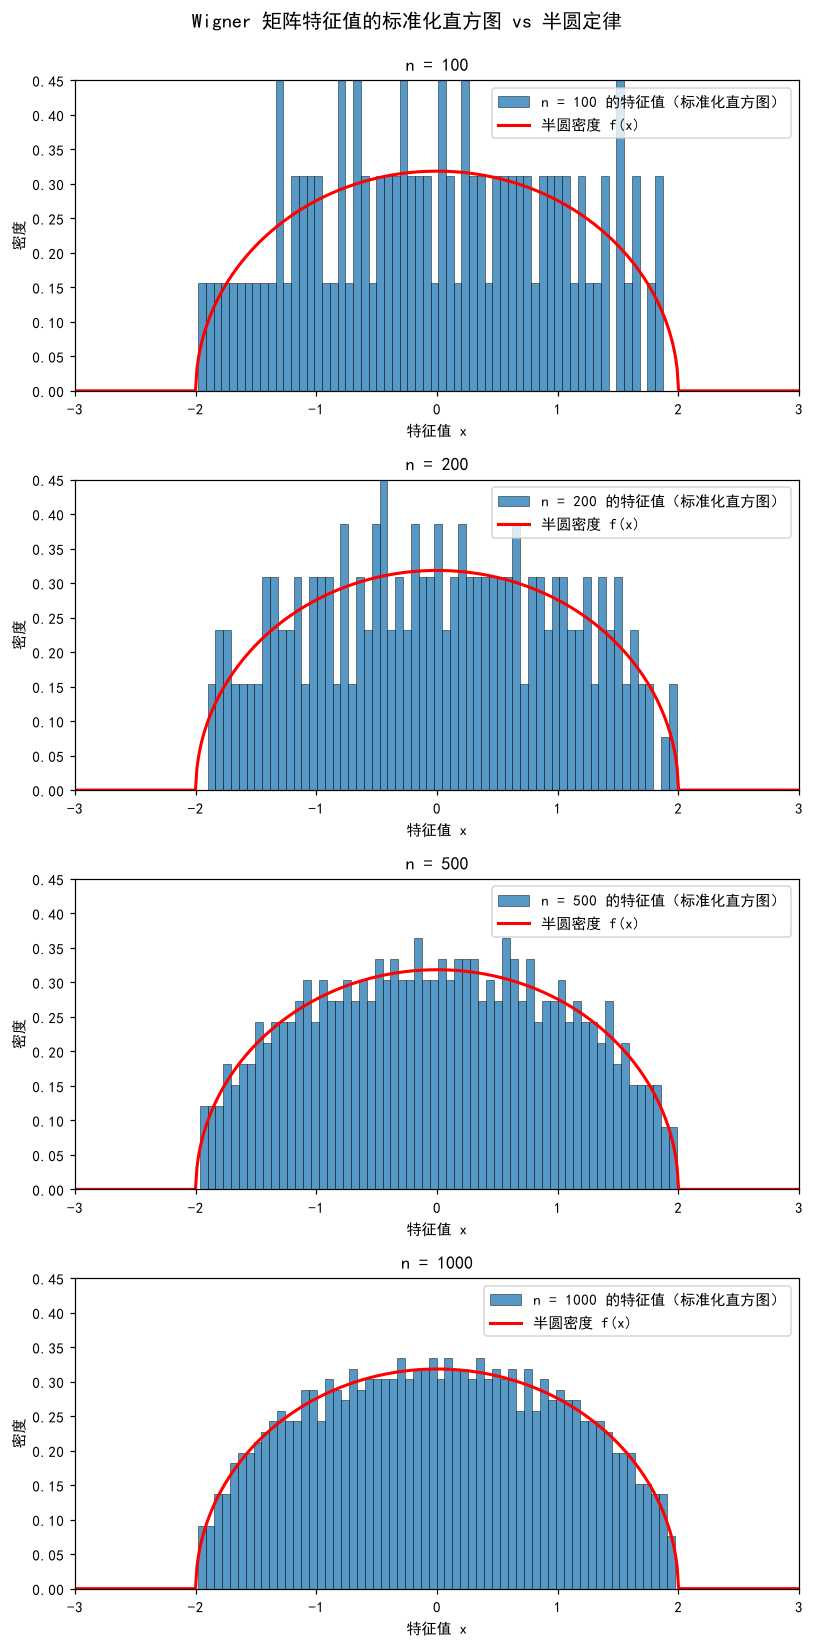

In [30]:
ns = [100, 200, 500, 1000]
xs = np.linspace(-3, 3, 500)
ys = wigner_density(xs)

fig, axes = plt.subplots(4, 1, figsize=(7.5, 15))

for ax, n in zip(axes, ns):
    eig = get_spectrum(generate_wigner(n))          # 特征值（已排序）
    ax.hist(eig, bins=60, density=True, color="tab:blue",
            alpha=0.75, edgecolor="k", linewidth=0.4,
            label=f"n = {n} 的特征值（标准化直方图）")
    ax.plot(xs, ys, color="red", linewidth=2, label="半圆密度 f(x)")
    ax.set_xlim(-3, 3)
    ax.set_ylim(0, 0.45)
    ax.set_xlabel("特征值 x")
    ax.set_ylabel("密度")
    ax.set_title(f"n = {n}")
    ax.legend(loc="upper right")

fig.suptitle("Wigner 矩阵特征值的标准化直方图 vs 半圆定律", y=0.995, fontsize=13)
plt.tight_layout()
plt.show()


根据图形说明：n 大约达到多少时，半圆密度能较好地拟合特征值分布？

- n = 100 时，直方图虽然大体呈拱形，但边缘（靠近 x = ±2）明显有“毛刺”，
  分布偏窄偏尖，与半圆密度的红色曲线还有肉眼可见的偏差。
- n = 200 时，整体轮廓已基本贴合曲线，只在中部和两端有轻微起伏。
- n = 500 时，直方图与半圆密度几乎重合，边界 ±2 处的截断也很干净。
- n = 1000 时，二者完全重合，噪声极小。

结论：n 大约达到 200 时半圆密度已能较好地拟合特征值分布；n ≥ 500 时拟合非常好（几乎无差别）。
随着 n 增大，特征值的支撑区间稳定在 [-2, 2]，端点处出现经典的“边缘涨落”现象，
这是半圆定律的典型特征。（可选 KS 检验见下一单元格，同样支持这一结论。）


KS检验（可选）

In [31]:
# 可选任务：Kolmogorov-Smirnov 检验，量化特征值分布与半圆密度 CDF 的差距
try:
    from scipy import stats

    def semicircle_cdf(x):
        """半圆密度的累积分布函数 F(x)，用于 KS 检验。"""
        x = np.clip(np.asarray(x, dtype=float), -2.0, 2.0)
        return 0.5 + (1.0 / (2.0 * np.pi)) * (x / 2.0 * np.sqrt(4.0 - x ** 2) + 2.0 * np.arcsin(x / 2.0))

    for n in ns:
        eig = get_spectrum(generate_wigner(n))
        res = stats.kstest(eig, semicircle_cdf)
        print(f"n={n:5d}  KS D = {res.statistic:.4f}   p-value = {res.pvalue:.4f}")
except ImportError:
    print("未安装 scipy，跳过可选任务（pip install scipy）")


n=  100  KS D = 0.0195   p-value = 1.0000
n=  200  KS D = 0.0133   p-value = 1.0000
n=  500  KS D = 0.0061   p-value = 1.0000
n= 1000  KS D = 0.0035   p-value = 1.0000


Conway 生命游戏

任务 1：`is_valid_board`

In [32]:
def is_valid_board(board):
    """判断是否为合法生命游戏棋盘：NumPy 二维数组且元素只能是 0 或 1。"""
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    if board.size == 0:                      # 空棋盘视为无效
        return False
    return bool(np.isin(board, [0, 1]).all())

# 自测
print(is_valid_board(np.array([[0, 1], [1, 0]])))        # True
print(is_valid_board(np.array([0, 1])) )                 # False（一维）
print(is_valid_board(np.array([[0, 2]])))                # False（含非法值）
print(is_valid_board([[0, 1]]))                          # False（不是 ndarray）
print(type(is_valid_board(np.array([[0, 1]]))))          # <class 'bool'>


True
False
False
False
<class 'bool'>


任务 2：`gol_step`

In [33]:
def gol_step(board):
    """返回棋盘下一代的 m×n 数组；邻居用 np.roll 实现环绕边界。"""
    if not is_valid_board(board):
        raise ValueError("输入不是合法的生命游戏棋盘（必须为二维 0/1 的 NumPy 数组）")

    # 8 个方向的邻居数之和（np.roll 天然实现上下左右的环绕）
    neighbors = sum(
        np.roll(np.roll(board, di, axis=0), dj, axis=1)
        for di in (-1, 0, 1) for dj in (-1, 0, 1)
        if (di, dj) != (0, 0)
    )

    # 规则：活细胞邻居 2 或 3 存活；死细胞邻居恰为 3 复活
    return ((neighbors == 3) | ((board == 1) & (neighbors == 2))).astype(int)

# 自测：滑翔机（glider）走一步
glider = np.zeros((5, 5), dtype=int)
glider[0, 1] = glider[1, 2] = glider[2, 0] = glider[2, 1] = glider[2, 2] = 1
print(glider)
print(gol_step(glider))
print("返回类型：", gol_step(glider).dtype, gol_step(glider).shape)

try:
    gol_step(np.array([[0, 2], [1, 1]]))
except ValueError as e:
    print("非法输入 -> ValueError:", e)


[[0 1 0 0 0]
 [0 0 1 0 0]
 [1 1 1 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
[[0 0 0 0 0]
 [1 0 1 0 0]
 [0 1 1 0 0]
 [0 1 0 0 0]
 [0 0 0 0 0]]
返回类型： int64 (5, 5)
非法输入 -> ValueError: 输入不是合法的生命游戏棋盘（必须为二维 0/1 的 NumPy 数组）


任务 3 + 演示：`draw_gol_board`

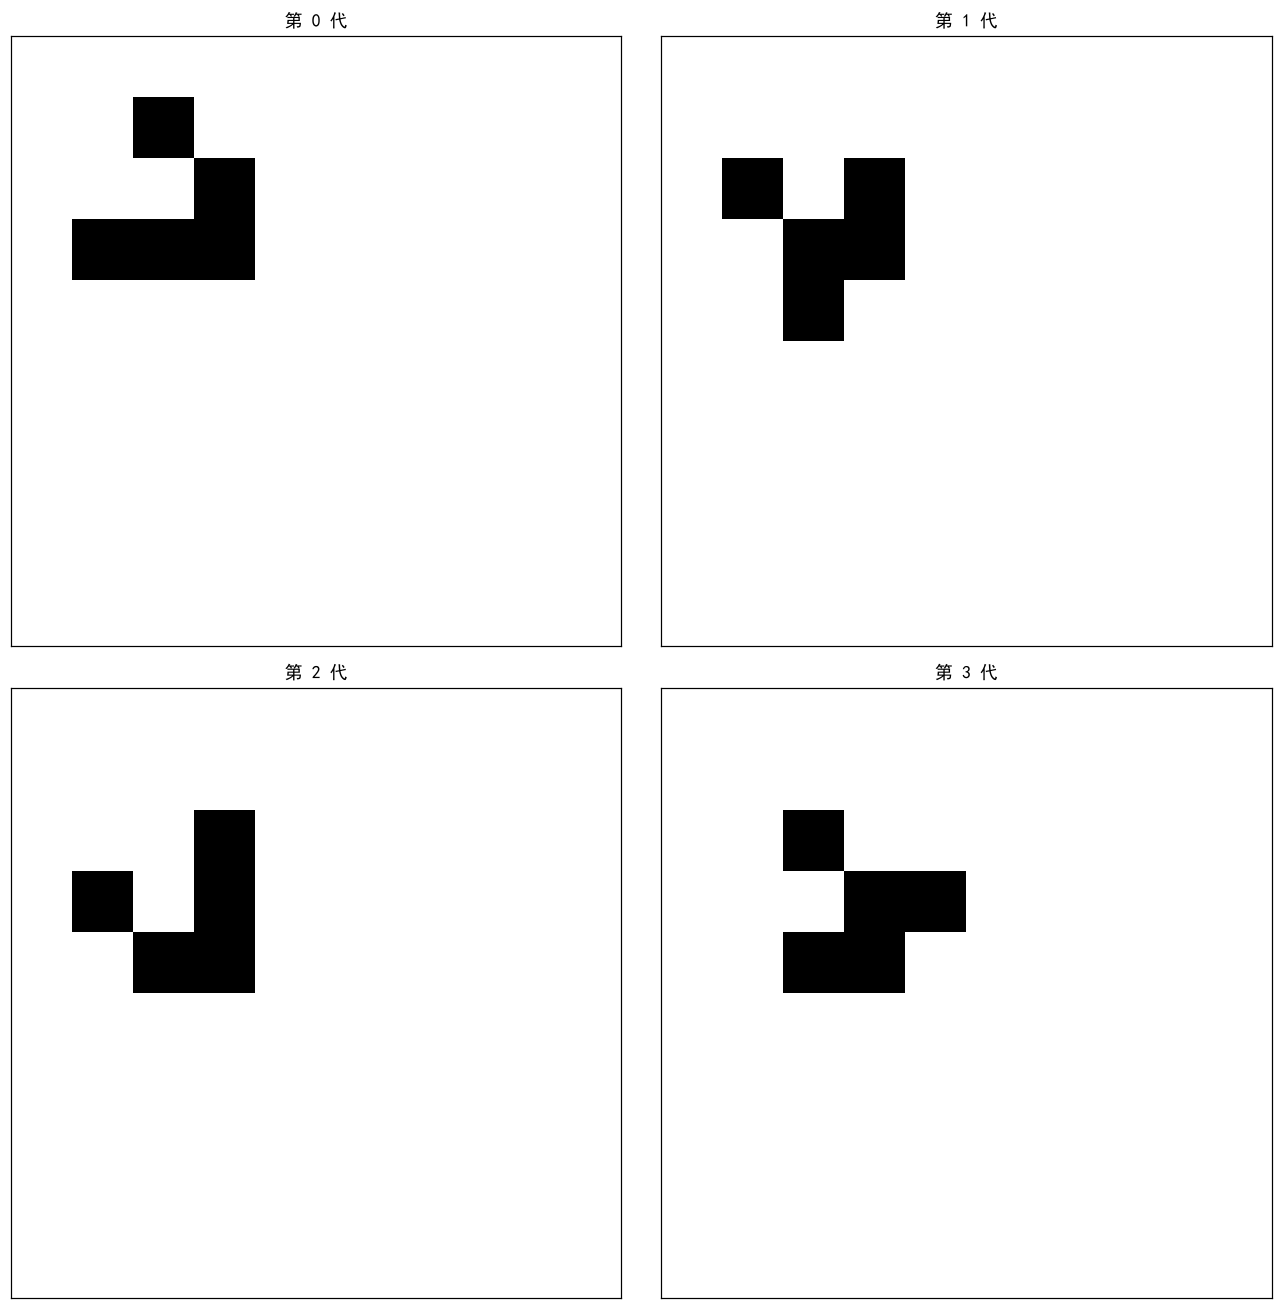

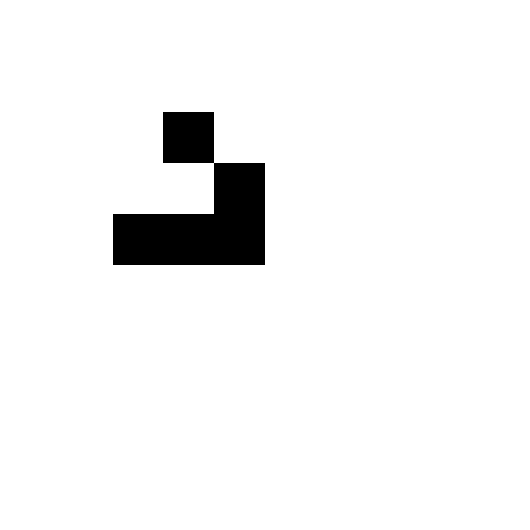

In [34]:
def draw_gol_board(board):
    """把棋盘画成 m×n 方格：活细胞黑、死细胞白，无网格线/轴标签/刻度。"""
    if not is_valid_board(board):
        raise ValueError("输入不是合法的生命游戏棋盘")

    plt.figure(figsize=(6, 6))
    # gray_r：0 -> 白，1 -> 黑
    plt.imshow(board, cmap="gray_r", interpolation="nearest", vmin=0, vmax=1)
    plt.xticks([])
    plt.yticks([])
    for spine in plt.gca().spines.values():   # 去掉边框
        spine.set_visible(False)
    plt.show()

# 演示：滑翔机演化 4 代（每代一张图）
board = np.zeros((10, 10), dtype=int)
board[1, 2] = board[2, 3] = board[3, 1] = board[3, 2] = board[3, 3] = 1

fig = plt.figure(figsize=(12, 12))
for i in range(4):
    ax = fig.add_subplot(2, 2, i + 1)
    ax.imshow(board, cmap="gray_r", interpolation="nearest", vmin=0, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"第 {i} 代")
    board = gol_step(board)
plt.tight_layout()
plt.show()

draw_gol_board(board)   # 单独调用一次，检查画出来是否无坐标轴、无网格线


使⽤ pandas DataFrame

任务 1：读取并观察数据

In [35]:
import pandas as pd

# Windows系统下载文件夹真实路径，Administrator是你的用户名
df = pd.read_csv(r"C:\Users\Administrator\Downloads\Iris.csv")
# 清除列名前后隐藏空格，解决KeyError
df.columns = df.columns.str.strip()

print("===== 任务1 结果 =====")
print(f"数据集数据点个数：{df.shape[0]}")
print("\n各列数据类型：")
print(df.dtypes)
print("\n列名列表：", df.columns.tolist())
print("\n花卉种类数量：", df["Species"].nunique())
print("花卉种类：", df["Species"].unique())
print("\n前5行数据：")
display(df.head())


===== 任务1 结果 =====
数据集数据点个数：150

各列数据类型：
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object

列名列表： ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

花卉种类数量： 3
花卉种类： <StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str

前5行数据：


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


任务1回答：
1. 数据点个数：150个。
2. 列名：Id, SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm, Species。
3. 数据类型：Id为int64；SepalLengthCm、SepalWidthCm、PetalLengthCm、PetalWidthCm为float64；Species为object。
4. 花卉一共3种：Iris‑setosa、Iris‑versicolor、Iris‑virginica。
5. 列含义：萼片长度、萼片宽度、花瓣长度、花瓣宽度，以及花卉种类。

任务 2：修改索引 34（第 35 行）、索引 37（第 38 行）

In [36]:
cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"]

# 作业文档指定修改内容
df.loc[34, cols] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37, cols] = [4.9, 3.6, 1.4, 0.1, "setosa"]

print("===== 修改后：索引34（原题第35行） =====")
print(df.loc[34])
print("\n===== 修改后：索引37（原题第38行） =====")
print(df.loc[37])


===== 修改后：索引34（原题第35行） =====
Id                   35
SepalLengthCm       4.9
SepalWidthCm        3.1
PetalLengthCm       1.5
PetalWidthCm        0.2
Species          setosa
Name: 34, dtype: object

===== 修改后：索引37（原题第38行） =====
Id                   38
SepalLengthCm       4.9
SepalWidthCm        3.6
PetalLengthCm       1.4
PetalWidthCm        0.1
Species          setosa
Name: 37, dtype: object


任务 3：新增 Petal.Ratio、Sepal.Ratio

In [37]:
# 花瓣长 / 花瓣宽
df["Petal.Ratio"] = df["PetalLengthCm"] / df["PetalWidthCm"]
# 萼片长 / 萼片宽
df["Sepal.Ratio"] = df["SepalLengthCm"] / df["SepalWidthCm"]

print("新增两列后表格形状：", df.shape)
df.head()


新增两列后表格形状： (150, 8)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Petal.Ratio,Sepal.Ratio
0,1,5.1,3.5,1.4,0.2,Iris-setosa,7.0,1.457143
1,2,4.9,3.0,1.4,0.2,Iris-setosa,7.0,1.633333
2,3,4.7,3.2,1.3,0.2,Iris-setosa,6.5,1.468750
3,4,4.6,3.1,1.5,0.2,Iris-setosa,7.5,1.483871
4,5,5.0,3.6,1.4,0.2,Iris-setosa,7.0,1.388889


保存修正后的 iris_corrected.csv

In [38]:
df.to_csv("iris_corrected.csv", index=False)
print("✅ 已保存文件 iris_corrected.csv")

# 校验保存结果
df_check = pd.read_csv("iris_corrected.csv")
df_check.columns = df_check.columns.str.strip()
print("\n校验修改过的两行：")
print(df_check.loc[[34, 37]])


✅ 已保存文件 iris_corrected.csv

校验修改过的两行：
    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm Species  \
34  35            4.9           3.1            1.5           0.2  setosa   
37  38            4.9           3.6            1.4           0.1  setosa   

    Petal.Ratio  Sepal.Ratio  
34          7.5     1.580645  
37         14.0     1.361111  


任务 5：分组统计 mean、median、min、max、std

In [39]:
agg_result = (
    df.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]]
    .agg(["mean", "median", "min", "max", "std"])
)
print("===== 按花卉种类分组统计结果 =====")
print(agg_result.round(4))


===== 按花卉种类分组统计结果 =====
                Petal.Ratio                                Sepal.Ratio  \
                       mean   median     min   max     std        mean   
Species                                                                  
Iris-setosa          6.7479   7.0000  2.6667  15.0  2.7187      1.4702   
Iris-versicolor      3.2428   3.2404  2.6667   4.1  0.3125      2.1604   
Iris-virginica       2.7807   2.6667  2.1250   4.0  0.4074      2.2305   
setosa              10.7500  10.7500  7.5000  14.0  4.5962      1.4709   

                                                 
                 median     min     max     std  
Species                                          
Iris-setosa      1.4631  1.2683  1.9565  0.1191  
Iris-versicolor  2.1613  1.7647  2.8182  0.2287  
Iris-virginica   2.1695  1.8235  2.9615  0.2470  
setosa           1.4709  1.3611  1.5806  0.1552  
